# Week 4 — Bayesian Inference for Observational Cosmology

### Web-lecture style edition

This version is formatted to read like the original teaching material:
short explanatory sections, displayed equations, compact callouts, and
examples immediately after the theory.

**Main scientific thread:** Pantheon+ Bayesian cosmology.

> **Extended reading / bridge to Week 5**
>
> The next subsection is included for context.
> Full MCMC diagnostics are taught in Week 5.

## Lecture map

### First half

- **0:00–0:15** — notation and why notation matters.
- **0:15–0:35** — Bayes' theorem and the inference problem.
- **0:35–1:05** — likelihood construction and astronomical errors.
- **1:05–1:35** — priors and prior predictive reasoning.
- **1:35–1:45** — break.

### Second half

- **1:45–2:10** — joint Pantheon+ posterior and grid computation.
- **2:10–2:30** — marginalization and credible regions.
- **2:30–2:45** — prior sensitivity.
- **2:45–2:58** — posterior prediction and model checking.
- **2:58–3:00** — bridge to Lab 04 and Week 5.

### Extended reading

The notebook also contains:

- a fuller likelihood taxonomy;
- intrinsic-scatter modelling;
- the parallax example;
- sequential Bayesian updating;
- an overview of posterior-computation methods;
- MCMC diagnostics as a Week 5 preview;
- posterior predictive \(p\)-values;
- a practical Bayesian-analysis checklist.

# 1. Notation: why it matters

Bayesian papers across astronomy, physics and statistics often use different symbols
for the same objects. The important point is not merely consistency of notation:
notation tells us **what is a function of what**.

For example,

\[ p(y\mid\theta) \]

emphasizes a probability distribution over possible data \(y\) for a fixed parameter
value \(\theta\).

The same mathematical quantity can be written as

\[ \mathcal L(\theta;y), \]

which emphasizes that the observed dataset \(y\) is fixed while the function is
examined over parameter space.

The numerical value is the same. The interpretation is different.

## 1.1 Notation used in this course

Use the following notation throughout Week 4.

- \(\theta\): unknown model parameters.
- \(y\) or \(D\): observed data.
- \(\tilde y\): replicated or future data.
- \(p(\theta)\): prior distribution.
- \(p(y\mid\theta)\): sampling model / likelihood.
- \(p(\theta\mid y)\): posterior distribution.
- \(p(\tilde y\mid y)\): posterior predictive distribution.

For Lab 04,

\[ \theta=(\Omega_m,M_B). \]

The observations are the released Pantheon+ standardized apparent magnitudes,
redshifts and covariance information.

## 1.2 Probability model versus likelihood

For fixed \(\theta\),

\[ p(y\mid\theta) \]

must satisfy

\[ \int p(y\mid\theta)\,dy=1. \]

This is a distribution over **possible datasets**.

Once the data are observed, \(y=y_{\rm obs}\) is fixed and we write

\[ \mathcal L(\theta;y_{\rm obs}) = p(y_{\rm obs}\mid\theta). \]

As a function of \(\theta\),

\[ \int \mathcal L(\theta;y_{\rm obs})\,d\theta \]

is not generally equal to one.

Therefore:

\[ \boxed{ \text{the likelihood is not a probability distribution over parameters}. }
\]

The posterior becomes a probability distribution over parameters only after
multiplying by a prior and normalizing.

### Instructor prompt

Ask:

> If the likelihood is larger at \(\Omega_m=0.30\) than at \(\Omega_m=0.40\),
> can we immediately say that \(\Omega_m=0.30\) is more probable?

**Answer:** not yet. We need the prior and posterior normalization.

This is the conceptual bridge from **Lab 03 maximum likelihood** to **Week 4 Bayesian
inference**.

# 2. The Bayesian inference problem

A complete Bayesian analysis needs:

1. a **likelihood** \(p(y\mid\theta)\);
2. a **prior** \(p(\theta)\);
3. a procedure for obtaining or approximating the **posterior** \(p(\theta\mid y)\).

The likelihood describes how parameters generate observations.

The prior describes which parameter values were plausible before conditioning on the
current dataset.

The posterior combines the two after we observe the data.

## 2.1 The joint distribution and derivation of Bayes' theorem

Before observing the present data,

\[ p(y,\theta) = p(y\mid\theta)p(\theta). \]

The same joint distribution can also be factorized as

\[ p(y,\theta) = p(\theta\mid y)p(y). \]

Equating them,

\[ p(y\mid\theta)p(\theta) = p(\theta\mid y)p(y). \]

Hence

\[ \boxed{ p(\theta\mid y) = \frac{p(y\mid\theta)p(\theta)} {p(y)} }. \]

The denominator is

\[ \boxed{ p(y) = \int p(y\mid\theta)p(\theta)\,d\theta } \]

and is called the **marginal likelihood** or **evidence**.

## 2.2 Why evidence appears

The posterior must integrate to one:

\[ \int p(\theta\mid y)\,d\theta=1. \]

Substituting Bayes' theorem gives

\[ 1 = \frac{1}{p(y)} \int p(y\mid\theta)p(\theta)\,d\theta. \]

Therefore the evidence is exactly the normalization constant required to make the
posterior a probability distribution.

For parameter estimation, \(p(y)\) does not depend on \(\theta\), so we usually work
with

\[ \boxed{ p(\theta\mid y) \propto p(y\mid\theta)p(\theta). } \]

Evidence becomes important in some model-comparison problems, which are not the focus
of this lab.

## 2.3 Cosmology translation

For the Pantheon+ teaching problem,

\[ \theta=(\Omega_m,M_B). \]

Thus

\[ p(\Omega_m,M_B\mid D) \propto p(D\mid\Omega_m,M_B) p(\Omega_m,M_B). \]

If the prior is factorized,

\[ p(\Omega_m,M_B) = p(\Omega_m)p(M_B), \]

then

\[ p(\Omega_m,M_B\mid D) \propto p(D\mid\Omega_m,M_B) p(\Omega_m)p(M_B). \]

That factorization is itself a modelling assumption.

# 3. The likelihood: your model of the data-generating process

The likelihood is where the scientific model meets the observational process.

A scientifically appropriate likelihood should reflect:

- what type of random variable was measured;
- the support of the data;
- the expected value under the model;
- measurement uncertainty;
- intrinsic physical scatter if present;
- covariance/dependence among observations.

A poor likelihood can produce a mathematically precise posterior that answers the
wrong scientific question.

## 3.1 Choosing a likelihood family

Start by asking:

> **What kind of random variable is the observed data product?**

Typical examples:

- **Counts** — photon counts or event counts
→ Poisson likelihood.

- **Binary outcomes** — detected / not detected
→ Bernoulli or Binomial likelihood.

- **Real-valued additive-noise measurements** — calibrated magnitudes,
radial velocities → often a Normal likelihood.

- **Strictly positive latent quantities** — some rates or scales
→ Gamma or LogNormal may be useful.

- **Probabilities or fractions** — efficiencies
→ Beta distributions are natural.

The likelihood must describe the **measurement process**.

A latent physical flux is positive, but a background-subtracted flux estimator can be
negative and approximately Gaussian. Therefore the appropriate likelihood is
determined by the actual data product, not only by the physical name of the latent
quantity.

## 3.2 Measurement-error structures

### Homoscedastic known errors

\[ y_i \sim \mathcal N(f_i(\theta),\sigma^2). \]

### Heteroscedastic known errors

\[ y_i \sim \mathcal N(f_i(\theta),\sigma_i^2). \]

### Unknown noise scale

\[ y_i \sim \mathcal N(f_i(\theta),\sigma^2), \qquad \sigma\sim p(\sigma). \]

### Intrinsic scatter

\[ y_i \sim \mathcal N \left( f_i(\theta), \sigma_i^2+\sigma_{\rm int}^2 \right). \]

If true intrinsic scatter exists but is omitted, the posterior can become
overconfident because the model attributes too much information to the measurements.

## 3.3 Why Gaussian normalization matters

The full Gaussian density is

\[ p(y_i\mid\mu_i,\sigma_i) = \frac{1}{\sqrt{2\pi\sigma_i^2}} \exp\left[
-\frac{(y_i-\mu_i)^2}
{2\sigma_i^2} \right]. \]

If \(\sigma_i\) is fixed, the normalization may be constant with respect to the fitted
parameters.

But if a fitted parameter enters the variance, for example

\[ \sigma_i^2+\sigma_{\rm int}^2, \]

then the normalization depends on \(\sigma_{\rm int}\) and cannot be dropped.

This is a general modelling lesson:

\[ \boxed{ \text{drop only terms that are truly constant with respect to all inferred
parameters}. } \]

## 3.4 Independent-data log-likelihood

If the observations are conditionally independent,

\[ p(y\mid\theta) = \prod_{i=1}^{N} p(y_i\mid\theta). \]

Taking logarithms,

\[ \log p(y\mid\theta) = \sum_{i=1}^{N} \log p(y_i\mid\theta). \]

For heteroscedastic Gaussian errors,

\[ \log p(y\mid\theta) =
-\frac12
\sum_i \left[ \frac{(y_i-f_i(\theta))^2}{\sigma_i^2}
+
\log(2\pi\sigma_i^2) \right]. \]

Working in log-space is both numerically safer and algebraically simpler.

## 3.5 From Gaussian likelihood to \(\chi^2\)

If all \(\sigma_i\) are known and fixed,

\[ \chi^2(\theta) = \sum_i \frac{(y_i-f_i(\theta))^2}{\sigma_i^2}. \]

Then

\[ \log\mathcal L(\theta) =
-\frac12\chi^2(\theta)
+
\text{constant}. \]

Therefore maximizing a Gaussian likelihood is equivalent to minimizing \(\chi^2\).

This is the direct Week 3 → Week 4 bridge:

\[ \boxed{ \chi^2 \rightarrow \mathcal L \rightarrow \mathcal L\,p(\theta) \rightarrow
p(\theta\mid y). } \]

## 3.6 Pantheon+ covariance likelihood

The teaching model is

\[ m_{B,i}^{\rm corr} = \mu(z_i;\Omega_m,H_0)+M_B+\epsilon_i. \]

Define

\[ \Delta(\Omega_m,M_B) = \mathbf m_B^{\rm corr}
-
\left[ \boldsymbol\mu(\mathbf z;\Omega_m,H_0)+M_B\mathbf1 \right]. \]

Assume

\[ \Delta \sim \mathcal N(\mathbf0,C). \]

Then

\[ p(D\mid\Omega_m,M_B) = \frac{ \exp[-\frac12\Delta^TC^{-1}\Delta] }{
(2\pi)^{N/2}|C|^{1/2} }. \]

Taking logs,

\[ \log\mathcal L =
-\frac12
\left[ \Delta^TC^{-1}\Delta
+
\log|C|
+
N\log(2\pi) \right]. \]

If the covariance \(C\) is fixed,

\[ \log|C|+N\log(2\pi) \]

is constant in \((\Omega_m,M_B)\).

Therefore,

\[ \boxed{ \log\mathcal L \propto
-\frac12\chi^2
} \]

with

\[ \boxed{ \chi^2 = \Delta^TC^{-1}\Delta. } \]

This is the likelihood used in Lab 04.

## 3.7 Why covariance matters

If

\[ C= \mathrm{diag}(\sigma_1^2,\ldots,\sigma_N^2), \]

then

\[ \Delta^TC^{-1}\Delta = \sum_i \frac{\Delta_i^2}{\sigma_i^2}. \]

If off-diagonal elements are non-zero, the observations carry correlated uncertainty.

Ignoring those terms changes the likelihood geometry.

Lab 04 uses **statistical covariance**. Week 5 adds the **statistical + systematic
covariance** and asks how the posterior changes.

# 4. The prior distribution

The prior

\[ p(\theta) \]

encodes information about parameter values before conditioning on the present data.

In astronomy that information can come from:

- physical boundaries;
- known scales;
- calibration knowledge;
- previous independent experiments;
- dimensional/positivity constraints.

A prior makes these assumptions explicit.

## 4.1 Prior taxonomy

### Proper

\[ \int p(\theta)\,d\theta=1. \]

### Improper

The integral is not finite.

### Informative

Concentrated because strong independent information exists.

### Weakly informative

Rules out absurd values while allowing the current data substantial influence.

### Flat / supposedly non-informative

Simple in one parameterization but generally not invariant under transformation.

### Conjugate

Chosen so prior and posterior belong to related mathematical families. Useful for
intuition, less common in realistic cosmology.

For this course, use proper priors unless there is a strong reason not to.

## 4.2 Why “flat” is parameterization-dependent

Let

\[ \phi=g(\theta). \]

Probability must be preserved:

\[ p_\phi(\phi)d\phi = p_\theta(\theta)d\theta. \]

Hence

\[ \boxed{ p_\phi(\phi) = p_\theta(\theta) \left| \frac{d\theta}{d\phi} \right|. } \]

Therefore a prior uniform in \(\theta\) is generally not uniform in \(\phi\).

Examples:

- distance vs parallax;
- \(\sigma\) vs \(\log\sigma\);
- mass vs log-mass.

A “flat” prior is a statement about a particular parameterization.

## 4.3 Two prior failure modes

### Too broad / vacuous

A prior assigns meaningful mass to parameter regions domain knowledge already rules
out.

Possible consequences:

- wasted computation;
- difficult posterior geometry;
- absurd prior predictive observations;
- weak identifiability.

### Too narrow / restrictive

A prior is so concentrated that realistic data cannot move the posterior.

Possible consequences:

- artificial precision;
- strong prior domination;
- reported “measurement” that largely reflects prior assumptions.

The target is not “the broadest possible prior.”

The target is a **defensible prior whose scientific implications are understood**.

## 4.4 Prior elicitation by parameter type

These are starting principles, not automatic recipes.

- **Location/intercept:** often a Normal prior centered on a physically motivated value.
- **Positive scale/scatter:** HalfNormal, Exponential, or a prior on \(\log\sigma\).
- **Slope:** often Normal if both signs are plausible.
- **Probability \(0<\eta<1\):** Beta.
- **Positive rate:** Gamma-family distributions can be natural.
- **Hard physical limit:** encode it explicitly in the support.

The correct check is not only “does the parameter range look reasonable?”

It is:

> What observations would this prior generate when combined with the likelihood?

## 4.5 Prior predictive checking

Before conditioning on the current observations,

\[ p(y) = \int p(y\mid\theta)p(\theta)\,d\theta. \]

This is the **prior predictive distribution**.

A practical workflow is:

1. draw \(\theta^{(s)}\sim p(\theta)\);
2. draw \(y^{(s)}\sim p(y\mid\theta^{(s)})\);
3. inspect whether those synthetic observations are scientifically plausible.

A prior that looks harmless in parameter space can still generate absurd observations.

Prior predictive checks therefore test the combined implications of the prior and
likelihood.

## 4.6 Lab 04 priors

Baseline:

\[ \Omega_m\sim U(0.10,0.60), \]

\[ M_B\sim U(-20.2,-18.2). \]

Inside the grid,

\[ p(\Omega_m,M_B)=\text{constant}. \]

Therefore the posterior shape is proportional to the likelihood inside the allowed
region.

But the prior still matters because it sets the support and boundaries.

## 4.7 Using previous measurements as priors

A previous result can become a prior when:

- its dataset is independent of the present dataset;
- the model is scientifically compatible;
- the uncertainty is trusted.

If an earlier independent analysis gives

\[ \theta\sim\mathcal N(\mu_0,\sigma_0^2), \]

that distribution can inform a new experiment.

### Double counting warning

Do not estimate a prior from the same data and then fit those same data again as
though the prior were independent.

That uses the information twice and produces an overconfident posterior.

## 4.8 Sequential Bayesian updating

For independent datasets \(y_1\) and \(y_2\),

\[ p(\theta\mid y_1) \propto p(y_1\mid\theta)p(\theta). \]

Use this as the prior for the second dataset:

\[ p(\theta\mid y_1,y_2) \propto p(y_2\mid\theta)p(\theta\mid y_1). \]

Substitute the first posterior:

\[ p(\theta\mid y_1,y_2) \propto p(y_2\mid\theta)p(y_1\mid\theta)p(\theta). \]

For independent information this is equivalent to analysing both datasets together.

# 5. Worked example: stellar distance from parallax

A star at distance \(d\) kpc has parallax

\[ \varpi=\frac1d \]

in milliarcseconds.

We observe a noisy parallax \(y\) with quoted uncertainty \(\sigma\).

The parameter of interest is \(d\); the measured quantity is \(y\).

## 5.1 Likelihood in parallax and distance space

Assume

\[ y\mid\varpi,\sigma \sim \mathcal N(\varpi,\sigma^2). \]

Since

\[ \varpi=\frac1d, \]

\[ p(y\mid d,\sigma) = \frac1{\sqrt{2\pi\sigma^2}} \exp\left[
-\frac{(y-1/d)^2}{2\sigma^2}
\right]. \]

This is Gaussian as a probability distribution over possible measurements \(y\) for
fixed \(d\).

As a function of distance for fixed measured \(y\), it is generally asymmetric because
of the nonlinear \(1/d\) transformation.

## 5.2 Three candidate distance priors

### Uniform in parallax

\[ p(\varpi)\propto1. \]

Since \(\varpi=1/d\),

\[ p(d) \propto \left|\frac{d\varpi}{dd}\right| = \frac1{d^2}. \]

### Uniform in distance

\[ p(d)\propto1 \]

over finite support.

### Exponentially decreasing space-density prior

\[ p(d)\propto d^2e^{-d/L}. \]

The \(d^2\) term reflects spherical-shell volume. The exponential term represents
decreasing stellar density at large distances. The scale \(L\) encodes domain
knowledge.

/tmp/ipykernel_1414/3948698982.py:23: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(p, x)


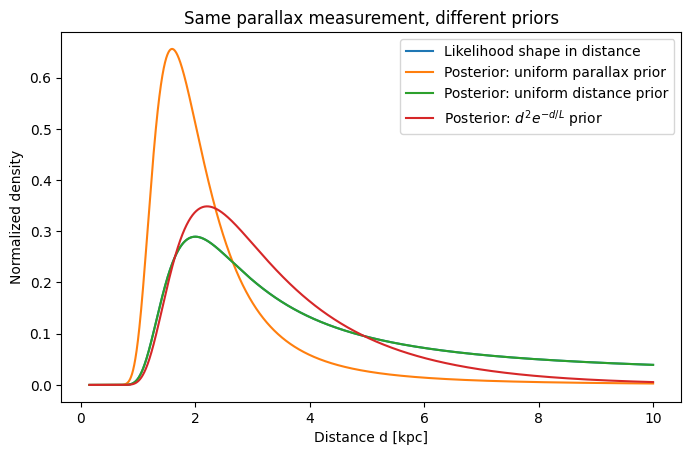

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Pedagogical example only.
y = 0.50      # measured parallax [mas]
sigma = 0.20  # quoted uncertainty [mas]
d = np.linspace(
    0.15,
    10.0,
    5000,
)  # kpc

log_like = -0.5 * ((y - 1.0 / d) / sigma) ** 2
like = np.exp(log_like - np.max(log_like))

prior_uniform_parallax = 1.0/d**2
prior_uniform_distance = np.ones_like(d)

L = 1.5
prior_space_density = d**2*np.exp(-d/L)

def normalize_density(x, p):
    area = np.trapz(p, x)
    return p/area

post_parallax = normalize_density(
    d,
    like * prior_uniform_parallax,
)
post_distance = normalize_density(
    d,
    like * prior_uniform_distance,
)
post_space = normalize_density(
    d,
    like * prior_space_density,
)

fig, ax = plt.subplots(figsize=(8,4.8))
ax.plot(
    d,
    normalize_density(d, like),
    label="Likelihood shape in distance",
)
ax.plot(
    d,
    post_parallax,
    label="Posterior: uniform parallax prior",
)
ax.plot(
    d,
    post_distance,
    label="Posterior: uniform distance prior",
)
ax.plot(
    d,
    post_space,
    label=r"Posterior: $d^2e^{-d/L}$ prior",
)
ax.set_xlabel("Distance d [kpc]")
ax.set_ylabel("Normalized density")
ax.set_title("Same parallax measurement, different priors")
ax.legend()
plt.show()

## 5.3 Lesson from the parallax example

The measurement and likelihood are identical in all three cases.

Only the prior changes.

Therefore different posteriors are expected because

\[ \boxed{ p(d\mid y) \propto p(y\mid d)p(d). } \]

The posterior is conditional on the complete model.

For skewed posteriors:

- the mode;
- the mean;
- the median;
- the credible interval

can describe different aspects of the same distribution.

A single symmetric error bar may be inadequate.

## 5.4 Cosmology translation

The same logic applies to \(\Omega_m\).

A broad prior lets the Pantheon+ likelihood dominate more strongly.

An informative prior such as

\[ \Omega_m\sim\mathcal N(0.30,0.03^2) \]

can make the posterior narrower or shift its center.

The key question is:

> How much of the posterior information comes from the present data, and how
> much comes from prior information?

# 6. Computing the posterior

Real astronomical posteriors are often not analytically normalizable.

Common numerical strategies include:

### Grid evaluation

Transparent and exact on the grid, but scales poorly with dimension.

### Laplace approximation

Approximates the posterior by a multivariate Gaussian near the mode. Fast, but weak
for skewness, boundaries and multimodality.

### Variational inference

Finds an approximate posterior from a simpler distribution family. Fast, but can miss
structure.

### MCMC

Generates samples distributed according to the posterior. Powerful but requires
convergence diagnostics.

Lab 04 uses a **2-D grid** because it is the simplest reliable method for this
problem.

## 6.1 Stable normalization on a grid

For grid cells \((i,j)\),

\[ a_{ij} = \log\mathcal L_{ij}
+
\log p(\Omega_{m,i})
+
\log p(M_{B,j}). \]

Then

\[ P_{ij} = \frac{e^{a_{ij}}} {\sum_{kl}e^{a_{kl}}}. \]

Direct exponentiation can underflow.

Use log-sum-exp:

\[ \log Z = a_{\max}
+
\log\sum_{ij} e^{a_{ij}-a_{\max}}. \]

Then

\[ \log P_{ij} = a_{ij}-\log Z. \]

This is why the Lab 04 code uses `logsumexp`.

## 6.2 Numerical checks for a grid posterior

Check:

- posterior normalization;
- grid resolution;
- whether probability mass reaches the boundaries;
- whether extending the grid changes the result;
- whether the joint shape is adequately resolved.

A computation that runs is not automatically a trustworthy inference.

## 6.3 Week 5 preview: convergence diagnostics

This is **extended reading**.

MCMC output must be checked.

Important diagnostics include:

### \(\hat R\)

Compares between-chain and within-chain variation.

### Effective sample size

Measures how many independent draws the autocorrelated chain is equivalent to.

### Divergences

Warn that the sampler may not have explored some posterior geometry reliably.

The broad lesson is:

\[ \boxed{ \text{a sampler that finishes is not necessarily a sampler that succeeded}.
} \]

Full derivation and use are reserved for Week 5.

## 6.4 Computational failure can indicate model failure

Difficult sampling may reflect:

- multiple modes;
- non-identifiability;
- strong nonlinear correlations;
- poor scaling;
- extreme/vacuous priors;
- pathological boundaries.

Before blaming the algorithm, examine the model.

# 7. Joint Pantheon+ posterior

The Week 4 posterior is

\[ p(\Omega_m,M_B\mid D) \propto \mathcal L(D\mid\Omega_m,M_B) p(\Omega_m)p(M_B). \]

The joint posterior shows:

- favored parameter combinations;
- parameter correlation;
- degeneracy direction;
- truncation by prior boundaries;
- asymmetry or multimodality.

Joint geometry is scientifically informative.

## 7.1 Why a correlation coefficient is not enough

A correlation coefficient compresses dependence into one number.

It does not describe:

- curvature;
- multiple modes;
- hard boundaries;
- skewness;
- nonlinear degeneracy.

Always inspect the joint posterior.

For \((\Omega_m,M_B)\), ask:

> Can changes in \(\Omega_m\) be compensated by changes in the
> absolute-magnitude calibration \(M_B\)?

# 8. Marginalization

If \(\Omega_m\) is the main estimand and \(M_B\) is a nuisance parameter,

\[ \boxed{ p(\Omega_m\mid D) = \int p(\Omega_m,M_B\mid D)\,dM_B. } \]

On a regular grid,

\[ p(\Omega_{m,i}\mid D) \propto \sum_jP_{ij}. \]

The common grid spacing cancels when the marginal is normalized.

## 8.1 Marginalization versus profiling

Profile likelihood:

\[ \mathcal L_{\rm prof}(\Omega_m) = \max_{M_B} \mathcal L(\Omega_m,M_B). \]

Bayesian marginalization:

\[ p(\Omega_m\mid D) = \int p(\Omega_m,M_B\mid D)\,dM_B. \]

Profiling selects the best nuisance parameter at each \(\Omega_m\).

Marginalization averages over all nuisance values according to posterior probability.

Therefore the Lab 03 profile-likelihood result and the Lab 04 posterior summary need
not coincide exactly.

## 8.2 Posterior mean, median and mode

### Mode

\[ \theta_{\rm mode} = \arg\max_\theta p(\theta\mid D). \]

### Mean

\[ E[\theta\mid D] = \int\theta p(\theta\mid D)d\theta. \]

### Median

\[ P(\theta<\theta_{\rm med}\mid D)=0.5. \]

For a symmetric Gaussian posterior they are nearly identical.

For skewed or multimodal posteriors they can differ substantially.

## 8.3 Credible intervals

Define

\[ F(\theta) = \int_{-\infty}^{\theta} p(\theta'\mid D)d\theta'. \]

A central 68% interval is

\[ \boxed{ [F^{-1}(0.16),F^{-1}(0.84)]. } \]

Bayesian interpretation:

> Conditional on the adopted likelihood, prior and model, 68% of posterior
> probability lies in this interval.

This is not the repeated-sampling interpretation of a frequentist confidence interval.

## 8.4 Joint credible regions

Define

\[ R_\alpha = \{\theta:p(\theta\mid D)\ge t_\alpha\}. \]

Choose the threshold \(t_\alpha\) so that

\[ \int_{R_\alpha} p(\theta\mid D)d\theta = \alpha. \]

Therefore a 68% posterior contour is defined by **enclosed posterior mass**, not by
choosing an arbitrary fraction of the peak density.

# 9. Prior sensitivity

Lab 04 compares:

\[ \Omega_m\sim U(0.10,0.60) \]

with

\[ \Omega_m\sim\mathcal N(0.30,0.03^2) \]

truncated to the grid.

Compare:

- posterior location;
- posterior width;
- credible interval;
- joint geometry.

If the posterior changes materially, then prior information is contributing materially
to the result.

## 9.1 How to report prior sensitivity

Useful statements include:

> “The posterior location is data-dominated, but the width remains
> prior-sensitive.”

or

> “The inference changes materially under a defensible alternative prior.”

The goal is not to eliminate prior influence.

The goal is to understand and report it.

# 10. Posterior predictive distribution

After fitting,

\[ \boxed{ p(\tilde y\mid y) = \int p(\tilde y\mid\theta) p(\theta\mid y) d\theta. }
\]

This is a distribution over **replicated or future data**.

It averages the likelihood over posterior uncertainty in the parameters.

## 10.1 Predictive uncertainty versus parameter uncertainty

Prediction contains at least:

1. **sampling / measurement variability** under the likelihood;
2. **parameter uncertainty** from the posterior;
3. possible **model misspecification**, which is not automatically captured by the model.

A tight posterior on \(\Omega_m\) does not imply equally tight prediction for a new SN
magnitude.

The new observation also has intrinsic/measurement scatter.

## 10.2 Important distinction in Lab 04

Lab 04 draws posterior parameter pairs

\[ (\Omega_m^{(s)},M_B^{(s)}) \]

and plots

\[ m_B^{(s)}(z) = \mu(z;\Omega_m^{(s)},H_0)
+
M_B^{(s)}. \]

These are **posterior-supported Hubble relations**.

A full posterior predictive replicated dataset would additionally draw

\[ \tilde{\mathbf m}^{(s)} \sim \mathcal N \left( \mathbf m_{\rm model}^{(s)}, C
\right). \]

Thus:

\[ \boxed{ \text{posterior-supported curves} \neq \text{full posterior predictive
observations}. } \]

# 11. Posterior predictive checks

A posterior predictive check asks:

> Does the fitted model generate observations with the same important features
> as the real data?

Procedure:

1. draw \(\theta^{(s)}\sim p(\theta\mid y)\);
2. draw replicated data
\[ \tilde y^{(s)}\sim p(\tilde y\mid\theta^{(s)}); \]
3. compare observed and replicated data.

## 11.1 Test statistics for PPCs

Choose a statistic \(T(y)\) that targets a possible model failure.

For Pantheon+:

\[ T_1=\mathrm{median}(r), \]

\[ T_2=\mathrm{SD}(r), \]

\[ T_3=\mathrm{MAD}(r), \]

\[ T_4=\text{redshift trend in residuals}, \]

\[ T_5=\text{fraction of large residual outliers}. \]

Good PPC statistics are scientifically interpretable and chosen because they probe a
specific failure mode.

## 11.2 Posterior predictive \(p\)-value

One diagnostic is

\[ p_B = P \left[ T(\tilde y)\ge T(y_{\rm obs}) \mid y_{\rm obs} \right]. \]

Approximate it by the fraction of posterior-predictive replicates with statistics at
least as large as observed.

Values near the center suggest the observed statistic is typical under the fitted
model.

Values near 0 or 1 indicate that the observation is extreme under the fitted model.

### Warning

A posterior predictive \(p\)-value is **not a classical frequentist p-value** and
should not be interpreted using a standard 0.05 significance rule.

## 11.3 Visual posterior predictive checks

Useful checks include:

### Distribution overlays

Observed histogram/density versus many replicated datasets.

### Residual plots

Residuals versus:

- redshift;
- predicted magnitude;
- survey;
- host property.

### Q–Q plots

Observed quantiles versus predicted quantiles.

### Conditional predictive checks

A model may fit globally but fail in a subset.

For cosmology, check for failures by redshift or survey.

## 11.4 What a failed PPC can teach us

Different failures suggest different model revisions.

- **Systematic mean offset**
Possible cause: calibration or intercept problem. Possible action: revise zero point
or covariate structure.

- **Predicted scatter too small**
Possible cause: missing intrinsic scatter or covariance. Possible action: add scatter
or systematic structure.

- **Heavy tails**
Possible cause: Gaussian likelihood is inadequate. Possible action: consider
Student-\(t\) or an outlier mixture.

- **Residual trend with redshift**
Possible cause: missing redshift-dependent physics or selection. Possible action:
revise the physical or selection model.

- **Failure only in one subpopulation**
Possible cause: population mixture. Possible action: consider a hierarchical or
mixture model.

A failed posterior predictive check is useful information.

The workflow should iterate:

\[ \boxed{ \text{model} \rightarrow \text{fit} \rightarrow \text{check} \rightarrow
\text{revise} }. \]

# 12. Extended example: multiple measurements of one latent quantity

**Extended reading / Week 5 bridge**

Suppose \(n\) stars in one cluster share a common distance \(d_{\rm cl}\), with

\[ y_i \sim \mathcal N \left( \frac1{d_{\rm cl}}, \sigma_i^2 \right). \]

Assuming conditional independence,

\[ p(\mathbf y\mid d_{\rm cl}) = \prod_i \mathcal N \left( y_i\mid1/d_{\rm
cl},\sigma_i^2 \right). \]

Define the total precision

\[ \tau^{-2} = \sum_i\sigma_i^{-2} \]

and weighted effective parallax

\[ \varpi_{\rm eff} = \tau^2 \sum_i \frac{y_i}{\sigma_i^2}. \]

Then the likelihood reduces to the form of one effective Gaussian measurement.

As independent information accumulates, the likelihood generally becomes more
informative relative to the prior.

## 12.1 The prior depends on the scientific population

A prior appropriate for a random field star is not automatically appropriate for a
known cluster member.

The symbol \(d\) is the same, but the scientific context is different.

Therefore:

\[ \boxed{ \text{priors describe the scientific population, not merely the parameter
name}. } \]

# 13. Practical Bayesian-analysis checklist

## Before fitting

- [ ] State the estimand.
- [ ] Identify the observed data product.
- [ ] Write the generative/forward model.
- [ ] Choose a likelihood consistent with the data type.
- [ ] Include heteroscedastic errors/covariance where required.
- [ ] Include intrinsic scatter if needed.
- [ ] Specify every prior and its support.
- [ ] Avoid absurdly broad priors.
- [ ] Avoid priors so restrictive that the data cannot move them.
- [ ] Run a prior predictive sanity check when feasible.

## During computation

### Grid

- [ ] Posterior is normalized.
- [ ] Grid resolution is adequate.
- [ ] Posterior mass does not depend on artificial grid boundaries.

### MCMC — Week 5

- [ ] Multiple chains agree.
- [ ] \(\hat R\) is satisfactory.
- [ ] Bulk/tail effective sample sizes are adequate.
- [ ] Trace plots are stationary and mixing.
- [ ] Divergences are absent or investigated.

## After fitting

- [ ] Inspect joint posterior geometry.
- [ ] Marginalize nuisance parameters correctly.
- [ ] Use posterior summaries appropriate to posterior shape.
- [ ] Test prior sensitivity.
- [ ] Generate posterior-supported or posterior-predictive observations.
- [ ] Check residual structure.
- [ ] Perform posterior predictive checks where feasible.
- [ ] Revise the model if systematic failures remain.

## Communicating the result

Report:

1. observed data and their uncertainty structure;
2. generative model;
3. likelihood;
4. parameters and nuisance parameters;
5. priors and motivation;
6. covariance treatment;
7. posterior geometry and summaries;
8. prior sensitivity;
9. predictive/model checks;
10. limitations.

A posterior without its likelihood and priors is not a reproducible scientific result.

# 14. Five-line statement for Lab 04

### Estimand

\[ p(\Omega_m,M_B\mid D) \]

and especially

\[ p(\Omega_m\mid D). \]

### Observed data

Pantheon+ standardized apparent magnitudes, redshifts and released statistical
covariance.

### Generative assumptions

\[ m_B^{\rm corr} = \mu(z;\Omega_m,H_0)+M_B+\epsilon, \]

with fixed \(H_0\) zero-point convention and

\[ \boldsymbol\epsilon\sim\mathcal N(\mathbf0,C). \]

### Uncertainty / selection

Statistical covariance is included. Systematic covariance is deferred to Week 5. Prior
support and the teaching sample mask condition the result.

### Validation / falsification

Distrust or revise the analysis if:

- posterior mass hits the grid/prior boundary;
- defensible priors materially change the conclusion;
- residuals show systematic trends;
- posterior-predictive behavior fails to resemble the data.

# 15. Bridge to Lab 04

Students will:

1. load real Pantheon+ data and statistical covariance;
2. compute \(\chi^2(\Omega_m,M_B)\);
3. construct the likelihood;
4. apply priors;
5. normalize the joint posterior;
6. inspect 2-D posterior geometry;
7. calculate 68% and 95% enclosed-probability contours;
8. marginalize over \(M_B\);
9. calculate credible intervals;
10. compare with Lab 03 profile likelihood;
11. test an informative prior;
12. inspect posterior-supported Hubble relations;
13. distinguish data information from prior/model assumptions.

# 16. Bridge to Week 5

Week 4 uses a two-dimensional grid so the posterior can be inspected directly.

Week 5 asks whether MCMC can recover the same target and how we diagnose the sampler.

We then add the full statistical+systematic covariance.

The principle is:

\[ \boxed{ \text{use the simplest reliable computation method that answers the
scientific question}. } \]

# 17. Final synthesis

Bayesian inference is a workflow, not a single algorithm.

\[ \boxed{ \text{scientific question} \rightarrow \text{generative model} \rightarrow
\text{likelihood} \rightarrow \text{prior} \rightarrow \text{posterior} \rightarrow
\text{prediction} \rightarrow \text{model criticism}. } \]

For Pantheon+:

\[ (\Omega_m,M_B) \rightarrow m_B^{\rm corr}(z) \rightarrow D \]

is the forward direction.

\[ D \rightarrow p(\Omega_m,M_B\mid D) \rightarrow p(\Omega_m\mid D) \]

is the inferential direction.

The posterior is conditional on

\[ \boxed{ \text{data}
+
\text{likelihood}
+
\text{prior}
+
\text{model}. } \]

The posterior predictive distribution takes us back to observation space, where the
fitted model can be tested against the real Universe.

# 18. Recommended reading

### Primary source adapted here
Andy Casey, **Practical Bayesian Inference in Astronomy**
<https://astrowizici.st/teaching/data-analysis/workflow_model_building/lecture-04/>

### Primary reference behind the Casey lecture
Eadie, G. M., Speagle, J. S., Cisewski-Kehe, J., et al. (2023),
**Practical Guidance for Bayesian Inference in Astronomy**, arXiv:2302.04703.

### Broader workflow
- Gelman et al. — Bayesian workflow
- Betancourt — principled Bayesian workflow
- Vehtari et al. — modern \(\hat R\) and effective sample size

### Course learning material
- Crete 06 — Bayesian 1
- Crete 06 — Bayes Ball
- Crete 06 — Bayesian 3

Read Casey for the **full modelling workflow**, this notebook for the **cosmology
translation**, and Lab 04 for the **real Pantheon+ implementation**.